# U-net

## Basic Data loading

In [30]:
import os
import numpy as np
import pandas as pd

DATA_DIR = "Data"

train_txt = os.path.join(DATA_DIR, "ECG5000_TRAIN.txt")
test_txt  = os.path.join(DATA_DIR, "ECG5000_TEST.txt")

assert os.path.exists(train_txt), f"Missing: {train_txt}"
assert os.path.exists(test_txt),  f"Missing: {test_txt}"

train = pd.read_csv(train_txt, header=None, delim_whitespace=True)
test  = pd.read_csv(test_txt,  header=None, delim_whitespace=True)

print("train shape:", train.shape)
print("test shape:", test.shape)
train.head()


C:\Users\Hontika\AppData\Local\Temp\ipykernel_27572\1826103362.py:13: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  train = pd.read_csv(train_txt, header=None, delim_whitespace=True)
C:\Users\Hontika\AppData\Local\Temp\ipykernel_27572\1826103362.py:14: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  test  = pd.read_csv(test_txt,  header=None, delim_whitespace=True)


train shape: (500, 141)
test shape: (4500, 141)


,0,1,2,3,4,5,6,7,8,9,...,131,132,133,134,135,136,137,138,139,140
0,1.0,-0.112522,-2.827204,-3.773897,-4.349751,-4.376041,-3.474986,-2.181408,-1.818286,-1.250522,...,0.160348,0.792168,0.933541,0.796958,0.578621,0.257740,0.228077,0.123431,0.925286,0.193137
1,1.0,-1.100878,-3.996840,-4.285843,-4.506579,-4.022377,-3.234368,-1.566126,-0.992258,-0.754680,...,0.560327,0.538356,0.656881,0.787490,0.724046,0.555784,0.476333,0.773820,1.119621,-1.436250
2,1.0,-0.567088,-2.593450,-3.874230,-4.584095,-4.187449,-3.151462,-1.742940,-1.490659,-1.183580,...,1.284825,0.886073,0.531452,0.311377,-0.021919,-0.713683,-0.532197,0.321097,0.904227,-0.421797
3,1.0,0.490473,-1.914407,-3.616364,-4.318823,-4.268016,-3.881110,-2.993280,-1.671131,-1.333884,...,0.491173,0.350816,0.499111,0.600345,0.842069,0.952074,0.990133,1.086798,1.403011,-0.383564
4,1.0,0.800232,-0.874252,-2.384761,-3.973292,-4.338224,-3.802422,-2.534510,-1.783423,-1.594450,...,0.966606,1.148884,0.958434,1.059025,1.371682,1.277392,0.960304,0.971020,1.614392,1.421456


## Split features/labels and remap labals to 0..C-1

In [31]:
X_train = train.iloc[:, 1:].values.astype(np.float32)
y_train = train.iloc[:, 0].values.astype(int)

X_test = test.iloc[:, 1:].values.astype(np.float32)
y_test = test.iloc[:, 0].values.astype(int)

classes = np.unique(y_train)
class_to_idx = {c:i for i,c in enumerate(classes)}
y_train = np.vectorize(class_to_idx.get)(y_train)
y_test  = np.vectorize(class_to_idx.get)(y_test)

num_classes = len(classes)
print("num_classes:", num_classes)
print("labels:", classes)



num_classes: 5
labels: [1 2 3 4 5]


## Normalize per sample

In [32]:
def zscore_per_sample(X, eps=1e-8):
    mu = X.mean(axis=1, keepdims=True)
    sd = X.std(axis=1, keepdims=True)
    return (X - mu) / (sd + eps)

X_train = zscore_per_sample(X_train)
X_test  = zscore_per_sample(X_test)


## Pytorch Datalset/Dataloader

In [33]:
import torch
from torch.utils.data import Dataset, DataLoader

class ECGDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X).unsqueeze(1)  # (N, 1, L)
        self.y = torch.from_numpy(y).long()
    def __len__(self): return len(self.X)
    def __getitem__(self, i): return self.X[i], self.y[i]

train_ds = ECGDataset(X_train, y_train)
test_ds  = ECGDataset(X_test, y_test)

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True, drop_last=True)
test_loader  = DataLoader(test_ds,  batch_size=256, shuffle=False)


## Train/Eval utils

In [34]:
import torch, torch.nn as nn
from tqdm.auto import tqdm
import numpy as np

device = "cuda" if torch.cuda.is_available() else "cpu"

def train_one_epoch(model, loader, opt, criterion, epoch=0):
    model.train()
    total_loss, correct, n = 0.0, 0, 0

    pbar = tqdm(loader, desc=f"Train {epoch:02d}", leave=False)
    for xb, yb in pbar:
        xb, yb = xb.to(device), yb.to(device)

        opt.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        opt.step()

        bs = xb.size(0)
        total_loss += loss.item() * bs
        correct += (logits.argmax(1) == yb).sum().item()
        n += bs

        pbar.set_postfix(
            loss=f"{total_loss/n:.4f}",
            acc=f"{correct/n:.3f}"
        )

    return total_loss/n, correct/n


@torch.no_grad()
def eval_model(model, loader, criterion, epoch=0):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    all_preds, all_y = [], []

    pbar = tqdm(loader, desc=f"Eval  {epoch:02d}", leave=False)
    for xb, yb in pbar:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        loss = criterion(logits, yb)

        bs = xb.size(0)
        total_loss += loss.item() * bs
        preds = logits.argmax(1)

        correct += (preds == yb).sum().item()
        n += bs

        all_preds.append(preds.cpu().numpy())
        all_y.append(yb.cpu().numpy())

        pbar.set_postfix(
            loss=f"{total_loss/n:.4f}",
            acc=f"{correct/n:.3f}"
        )

    all_preds = np.concatenate(all_preds)
    all_y = np.concatenate(all_y)
    return total_loss/n, correct/n, all_y, all_preds


def fit(model, train_loader, test_loader, epochs=30, lr=1e-3, weight_decay=1e-4):
    model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss()

    best_acc = 0.0
    best_state = None
    history = []

    for ep in range(epochs):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, opt, criterion, epoch=ep)
        te_loss, te_acc, _, _ = eval_model(model, test_loader, criterion, epoch=ep)

        history.append((tr_loss, tr_acc, te_loss, te_acc))

        if te_acc > best_acc:
            best_acc = te_acc
            best_state = {k: v.detach().cpu() for k, v in model.state_dict().items()}

        print(f"Epoch {ep:02d}/{epochs-1}  "
              f"train: loss {tr_loss:.4f}, acc {tr_acc:.3f} | "
              f"test: loss {te_loss:.4f}, acc {te_acc:.3f}")

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, history

## Grad-CAM utils

In [35]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

class GradCAM1D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, inp, out):
            self.activations = out.detach()

        def backward_hook(module, grad_in, grad_out):
            self.gradients = grad_out[0].detach()

        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_full_backward_hook(backward_hook)

    def __call__(self, x, class_idx=None):
        """
        x: (1, 1, L)
        returns cam: (L,)
        """
        self.model.zero_grad()
        logits = self.model(x)
        if class_idx is None:
            class_idx = logits.argmax(1).item()

        score = logits[:, class_idx]
        score.backward()

        # activations: (1, C, L') gradients: (1, C, L')
        A = self.activations
        dA = self.gradients

        # global-average pool gradients over time to get weights per channel
        weights = dA.mean(dim=-1, keepdim=True)  # (1, C, 1)

        cam = (weights * A).sum(dim=1)  # (1, L')
        cam = F.relu(cam)

        # upsample cam to input length
        cam = F.interpolate(cam.unsqueeze(1), size=x.shape[-1], mode="linear", align_corners=False)
        cam = cam.squeeze().cpu().numpy()

        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, class_idx, logits.softmax(1).detach().cpu().numpy()

def show_gradcam_1d(model, dataset, idx, class_names=None, target_layer=None):
    model.eval()
    x, y = dataset[idx]
    x_in = x.unsqueeze(0).to(device)

    # pick default layer if not provided
    if target_layer is None:
        # try to use last conv in decoder (dec1) if exists
        target_layer = getattr(model, "dec1", None)
        if target_layer is not None and hasattr(target_layer, "net"):
            # last Conv1d in that block
            target_layer = target_layer.net[3]
        else:
            # fallback: last Conv1d we can find
            convs = [m for m in model.modules() if isinstance(m, torch.nn.Conv1d)]
            target_layer = convs[-1]

    cam_engine = GradCAM1D(model, target_layer)
    cam, pred_idx, probs = cam_engine(x_in)

    sig = x.squeeze().numpy()
    L = sig.shape[0]

    plt.figure(figsize=(10,3))
    plt.plot(sig, label="ECG")
    plt.fill_between(np.arange(L), sig.min(), sig.max(), where=cam>0,
                     alpha=0.3, step="mid")
    plt.title(
        f"Grad-CAM 1D | true={y.item()} pred={pred_idx} "
        + (f"({class_names[pred_idx]})" if class_names else "")
    )
    plt.legend()
    plt.show()

    print("Class probs:", probs[0])


## Model 1: Compact 1D U-net

In [36]:
class ConvBlock1D(nn.Module):
    def __init__(self, cin, cout, k=3, p=1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(cin, cout, k, padding=p),
            nn.BatchNorm1d(cout),
            nn.ReLU(),
            nn.Conv1d(cout, cout, k, padding=p),
            nn.BatchNorm1d(cout),
            nn.ReLU(),
        )
    def forward(self, x): return self.net(x)

class UNet1DClassifier(nn.Module):
    def __init__(self, in_ch=1, base=32, num_classes=5, dropout=0.0):
        super().__init__()
        self.enc1 = ConvBlock1D(in_ch, base)
        self.down1 = nn.MaxPool1d(2)
        self.enc2 = ConvBlock1D(base, base*2)
        self.down2 = nn.MaxPool1d(2)
        self.enc3 = ConvBlock1D(base*2, base*4)

        self.up2 = nn.ConvTranspose1d(base*4, base*2, 2, stride=2)
        self.dec2 = ConvBlock1D(base*4, base*2)
        self.up1 = nn.ConvTranspose1d(base*2, base, 2, stride=2)
        self.dec1 = ConvBlock1D(base*2, base)

        # classifier head
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(base, num_classes)
        )

    def forward(self, x):
        e1 = self.enc1(x)      # (B, base, L)
        e2 = self.enc2(self.down1(e1))  # (B, 2base, L/2)
        e3 = self.enc3(self.down2(e2))  # (B, 4base, L/4)

        d2 = self.up2(e3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.head(d1)

## Model 2: 1D U-net with FNO bottleneck

In [37]:
class SpectralConv1d(nn.Module):
    """
    1D spectral conv: FFT -> keep modes -> complex linear map -> iFFT
    """
    def __init__(self, in_channels, out_channels, modes):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.modes = modes
        scale = 1 / (in_channels * out_channels)
        self.weights = nn.Parameter(scale * torch.randn(in_channels, out_channels, modes, dtype=torch.cfloat))

    def forward(self, x):
        # x: (B, C, L)
        B, C, L = x.shape
        x_ft = torch.fft.rfft(x, dim=-1)  # (B, C, L//2+1)
        out_ft = torch.zeros(B, self.out_channels, x_ft.size(-1), dtype=torch.cfloat, device=x.device)

        m = min(self.modes, x_ft.size(-1))
        out_ft[:, :, :m] = torch.einsum("bci,coi->boi", x_ft[:, :, :m], self.weights[:, :, :m])
        x = torch.fft.irfft(out_ft, n=L, dim=-1)
        return x

class FNOBlock1d(nn.Module):
    def __init__(self, width, modes):
        super().__init__()
        self.spec = SpectralConv1d(width, width, modes)
        self.pw = nn.Conv1d(width, width, 1)
        self.bn = nn.BatchNorm1d(width)
    def forward(self, x):
        x = self.spec(x) + self.pw(x)
        return F.relu(self.bn(x))

class UNetFNO1DClassifier(nn.Module):
    def __init__(self, in_ch=1, base=32, num_classes=5, modes=16, fno_layers=2, dropout=0.0):
        super().__init__()
        self.enc1 = ConvBlock1D(in_ch, base)
        self.down1 = nn.MaxPool1d(2)
        self.enc2 = ConvBlock1D(base, base*2)
        self.down2 = nn.MaxPool1d(2)
        self.enc3 = ConvBlock1D(base*2, base*4)

        self.fno = nn.Sequential(*[FNOBlock1d(base*4, modes) for _ in range(fno_layers)])

        self.up2 = nn.ConvTranspose1d(base*4, base*2, 2, stride=2)
        self.dec2 = ConvBlock1D(base*4, base*2)
        self.up1 = nn.ConvTranspose1d(base*2, base, 2, stride=2)
        self.dec1 = ConvBlock1D(base*2, base)

        self.head = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(base, num_classes)
        )

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.down1(e1))
        e3 = self.enc3(self.down2(e2))

        b = self.fno(e3)

        d2 = self.up2(b)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.head(d1)


## Training

In [ ]:
unet_model, hist_unet = fit(unet_model, train_loader, test_loader, epochs=40, lr=1e-3)
unet_fno_model, hist_fno = fit(unet_fno_model, train_loader, test_loader, epochs=40, lr=1e-3)

Epoch 00/39  train: loss 0.1191, acc 0.956 | test: loss 0.3399, acc 0.928


Epoch 01/39  train: loss 0.0966, acc 0.966 | test: loss 0.2407, acc 0.935


Epoch 02/39  train: loss 0.0987, acc 0.966 | test: loss 0.2588, acc 0.937


Epoch 03/39  train: loss 0.0774, acc 0.977 | test: loss 0.2481, acc 0.940


Epoch 04/39  train: loss 0.0699, acc 0.974 | test: loss 0.2487, acc 0.937


...

Epoch 12/39  train: loss 0.0395, acc 0.995 | test: loss 0.2261, acc 0.938


Epoch 13/39  train: loss 0.0289, acc 0.997 | test: loss 0.2264, acc 0.938


Epoch 14/39  train: loss 0.0275, acc 0.995 | test: loss 0.2301, acc 0.938


Epoch 15/39  train: loss 0.0301, acc 0.995 | test: loss 0.2313, acc 0.936


Eval  16:  33%|███▎      | 6/18 [00:00<00:00, 24.80it/s, acc=0.996, loss=0.0175]

## Evaluation

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

def plot_confusion(cm, class_names, normalize=False, title="Confusion matrix"):
    if normalize:
        cm = cm.astype(float) / (cm.sum(axis=1, keepdims=True) + 1e-12)

    fig, ax = plt.subplots(figsize=(6,5))
    im = ax.imshow(cm, interpolation="nearest")
    ax.figure.colorbar(im, ax=ax)

    ax.set(
        xticks=np.arange(len(class_names)),
        yticks=np.arange(len(class_names)),
        xticklabels=class_names,
        yticklabels=class_names,
        title=title,
        ylabel="True label",
        xlabel="Predicted label",
    )
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

    fmt = ".2f" if normalize else "d"
    thresh = cm.max() * 0.6
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(
                j, i, format(cm[i, j], fmt),
                ha="center", va="center",
                color="white" if cm[i, j] > thresh else "black",
                fontsize=11
            )
    fig.tight_layout()
    plt.show()


def eval_and_plot(model, loader, class_names, title_prefix="Model"):
    crit = nn.CrossEntropyLoss()
    _, acc, y_true, y_pred = eval_model(model, loader, crit)
    print(f"{title_prefix} test acc: {acc:.4f}\n")

    cm = confusion_matrix(y_true, y_pred)

    plot_confusion(cm, class_names, normalize=False,
                   title=f"{title_prefix} — Confusion (counts)")
    plot_confusion(cm, class_names, normalize=True,
                   title=f"{title_prefix} — Confusion (row-normalized)")

    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
    return y_true, y_pred, acc


U-Net test acc: 0.9367



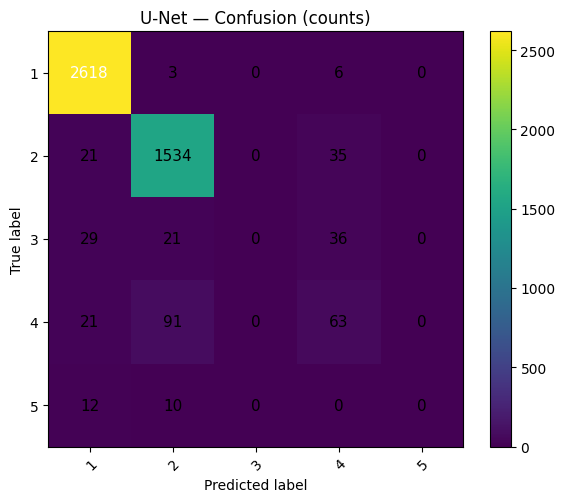

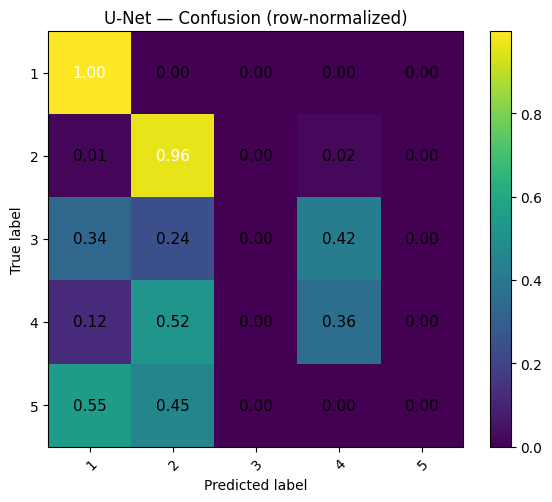

e:\Repos\U-net_cikk\unet\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
e:\Repos\U-net_cikk\unet\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
e:\Repos\U-net_cikk\unet\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


              precision    recall  f1-score   support

           1     0.9693    0.9966    0.9827      2627
           2     0.9247    0.9648    0.9443      1590
           3     0.0000    0.0000    0.0000        86
           4     0.4500    0.3600    0.4000       175
           5     0.0000    0.0000    0.0000        22

    accuracy                         0.9367      4500
   macro avg     0.4688    0.4643    0.4654      4500
weighted avg     0.9100    0.9367    0.9229      4500



U-Net + FNO test acc: 0.9231



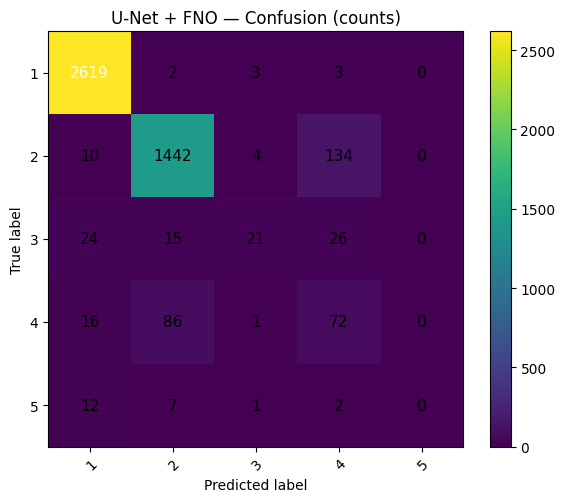

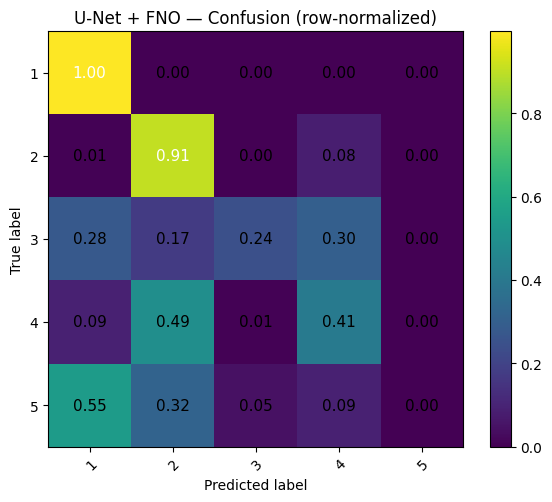

              precision    recall  f1-score   support

           1     0.9769    0.9970    0.9868      2627
           2     0.9291    0.9069    0.9179      1590
           3     0.7000    0.2442    0.3621        86
           4     0.3038    0.4114    0.3495       175
           5     0.0000    0.0000    0.0000        22

    accuracy                         0.9231      4500
   macro avg     0.5820    0.5119    0.5233      4500
weighted avg     0.9238    0.9231    0.9209      4500



e:\Repos\U-net_cikk\unet\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
e:\Repos\U-net_cikk\unet\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
e:\Repos\U-net_cikk\unet\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [ ]:
class_names = [str(c) for c in classes]  # e.g. ['1','2','3','4','5']

y_true_u, y_pred_u, acc_u = eval_and_plot(unet_model, test_loader, class_names, "U-Net")
y_true_f, y_pred_f, acc_f = eval_and_plot(unet_fno_model, test_loader, class_names, "U-Net + FNO")

## Training Curves

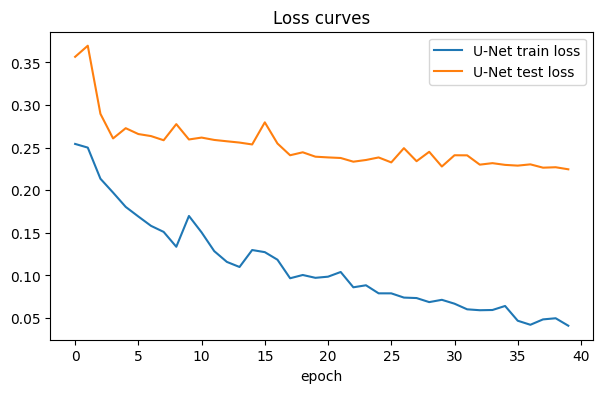

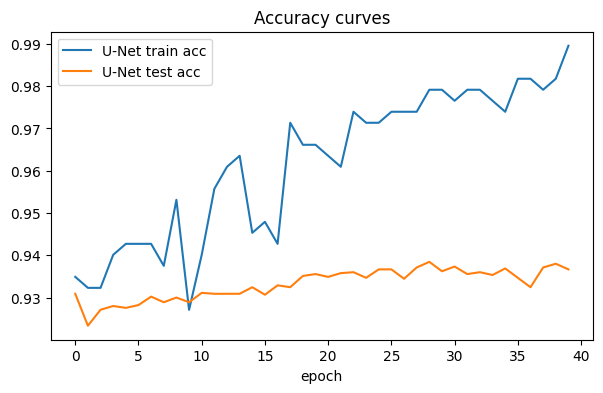

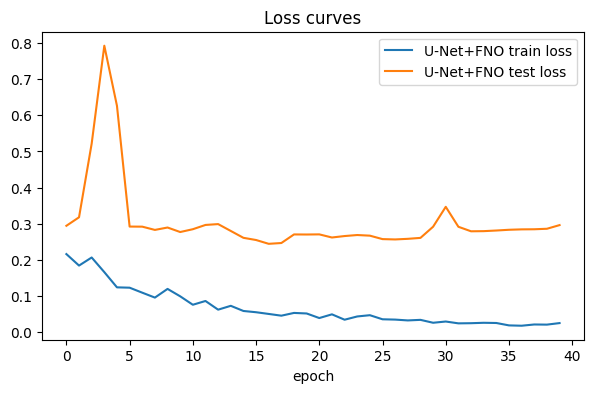

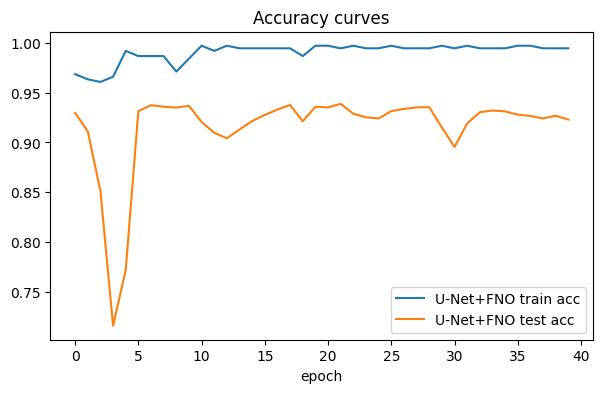

In [ ]:
def plot_history(hist, label="model"):
    hist = np.array(hist)
    tr_loss, tr_acc, te_loss, te_acc = hist.T

    plt.figure(figsize=(7,4))
    plt.plot(tr_loss, label=f"{label} train loss")
    plt.plot(te_loss, label=f"{label} test loss")
    plt.title("Loss curves")
    plt.xlabel("epoch")
    plt.legend()
    plt.show()

    plt.figure(figsize=(7,4))
    plt.plot(tr_acc, label=f"{label} train acc")
    plt.plot(te_acc, label=f"{label} test acc")
    plt.title("Accuracy curves")
    plt.xlabel("epoch")
    plt.legend()
    plt.show()

plot_history(hist_unet, "U-Net")
plot_history(hist_fno, "U-Net+FNO")



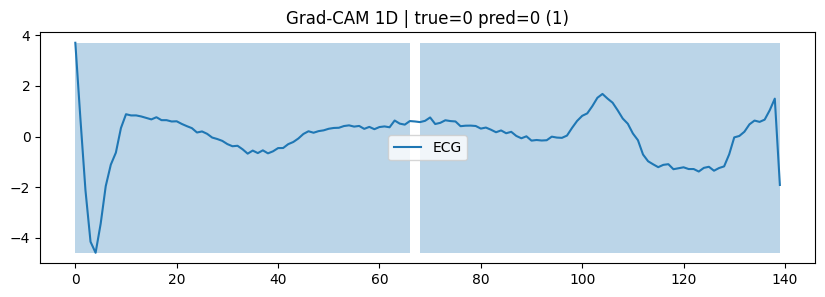

Class probs: [9.9271071e-01 1.4480411e-03 8.4789906e-04 2.2011050e-03 2.7922371e-03]


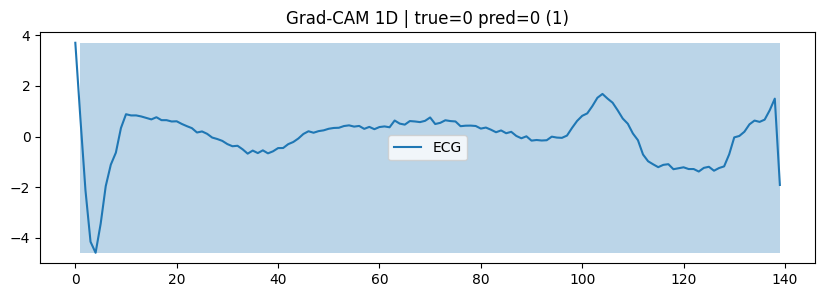

Class probs: [0.99082375 0.0012545  0.00235392 0.00276662 0.00280122]


In [ ]:
class_names = [str(c) for c in classes]  # original labels 1..5
show_gradcam_1d(unet_model, test_ds, idx=0, class_names=class_names)
show_gradcam_1d(unet_fno_model, test_ds, idx=0, class_names=class_names)


## Hyperparameter tuning

Shared:

- base (channels): 16, 32, 48, 64
- lr: 1e-3, 5e-4, 3e-4
- weight_decay: 0, 1e-5, 1e-4, 5e-4
- epochs: fixed (30–60); not a search target unless you want early stopping

Base U-Net-specific:

- dropout: 0.0, 0.1, 0.2, 0.3 (we’ll add it optionally)
- kernel_size: 3 or 5 (optional; more invasive)

FNO-specific:

- modes: 8, 12, 16, 24, 32
- fno_layers: 1, 2, 3

### Filesystem + save helpers

In [ ]:
import os, json, csv, time
from pathlib import Path
import pandas as pd

MODELS_DIR = Path("models")
BASE_DIR = MODELS_DIR / "base_unet"
FNO_DIR  = MODELS_DIR / "unet_fno"
MODELS_DIR.mkdir(exist_ok=True)
BASE_DIR.mkdir(exist_ok=True)
FNO_DIR.mkdir(exist_ok=True)

LEADERBOARD_PATH = MODELS_DIR / "leaderboard.csv"

def next_run_dir(model_type):
    parent = BASE_DIR if model_type=="base_unet" else FNO_DIR
    runs = sorted([p for p in parent.glob("run_*") if p.is_dir()])
    run_id = len(runs) + 1
    run_dir = parent / f"run_{run_id:03d}"
    run_dir.mkdir(parents=True, exist_ok=False)
    return run_dir, run_id

def save_run(model, model_type, config, metrics):
    run_dir, run_id = next_run_dir(model_type)

    # save weights
    torch.save(model.state_dict(), run_dir / "model.pt")

    # save config/metrics
    with open(run_dir / "config.json", "w") as f:
        json.dump(config, f, indent=2)

    with open(run_dir / "metrics.json", "w") as f:
        json.dump(metrics, f, indent=2)

    # append to leaderboard
    row = {
        "timestamp": time.strftime("%Y-%m-%d %H:%M:%S"),
        "model_type": model_type,
        "run_id": run_id,
        **config,
        **metrics
    }

    df = pd.DataFrame([row])
    if LEADERBOARD_PATH.exists():
        df.to_csv(LEADERBOARD_PATH, mode="a", header=False, index=False)
    else:
        df.to_csv(LEADERBOARD_PATH, index=False)

    return run_dir

def best_per_type():
    if not LEADERBOARD_PATH.exists():
        print("No leaderboard yet.")
        return None
    df = pd.read_csv(LEADERBOARD_PATH)
    out = df.sort_values("test_acc", ascending=False).groupby("model_type").head(1)
    return out


### Hyperparameter script (Grid Search)

In [ ]:
# ======== GRIDSEARCH (single block) ========

from itertools import product
import torch
import torch.nn as nn
import pandas as pd

# -------------------------
# 1) Define parameter grids
# -------------------------
grid_shared = {
    "base": [16, 32, 48],          # channel width of U-Net
    "lr": [1e-3, 5e-4],            # learning rate
    "weight_decay": [0.0, 1e-4],   # L2 regularization
    "dropout": [0.0, 0.1, 0.2],    # head dropout
}

grid_fno = {
    "modes": [8, 16, 24],          # kept Fourier modes
    "fno_layers": [1, 2],          # number of FNO blocks
}

# -------------------------
# 2) Grid expansion helper
# -------------------------
def expand_grid(grid_dict):
    keys = list(grid_dict.keys())
    vals = list(grid_dict.values())
    return [dict(zip(keys, v)) for v in product(*vals)]

# -------------------------
# 3) Build model from config
# -------------------------
def build_model(model_type, cfg):
    if model_type == "base_unet":
        return UNet1DClassifier(
            in_ch=1,
            base=cfg["base"],
            num_classes=num_classes,
            dropout=cfg["dropout"]
        )
    elif model_type == "unet_fno":
        return UNetFNO1DClassifier(
            in_ch=1,
            base=cfg["base"],
            num_classes=num_classes,
            modes=cfg["modes"],
            fno_layers=cfg["fno_layers"],
            dropout=cfg["dropout"]
        )
    else:
        raise ValueError("model_type must be 'base_unet' or 'unet_fno'")

# -------------------------
# 4) Run one experiment
# -------------------------
def run_one_experiment(model_type, cfg, epochs=40):
    model = build_model(model_type, cfg)

    model, hist = fit(
        model,
        train_loader,
        test_loader,
        epochs=epochs,
        lr=cfg["lr"],
        weight_decay=cfg["weight_decay"]
    )

    crit = nn.CrossEntropyLoss()
    _, test_acc, y_true, y_pred = eval_model(model, test_loader, crit)

    metrics = {
        "test_acc": float(test_acc),
        "epochs": epochs,
        "params_million": sum(p.numel() for p in model.parameters()) / 1e6
    }

    save_run(model, model_type, cfg, metrics)
    return cfg, metrics

# -------------------------
# 5) Full gridsearch
# -------------------------
def grid_search(model_type, epochs=40):
    shared_cfgs = expand_grid(grid_shared)

    if model_type == "base_unet":
        cfgs = shared_cfgs
    else:
        fno_cfgs = expand_grid(grid_fno)
        cfgs = []
        for s in shared_cfgs:
            for f in fno_cfgs:
                c = dict(s)
                c.update(f)
                cfgs.append(c)

    print(f"{model_type}: {len(cfgs)} total configs")

    results = []
    for i, cfg in enumerate(cfgs, 1):
        print(f"\n[{i}/{len(cfgs)}] {model_type} cfg={cfg}")
        cfg_out, metrics = run_one_experiment(model_type, cfg, epochs=epochs)
        results.append((cfg_out, metrics))
        print("=> metrics:", metrics)

    return results

# -------------------------
# 6) Run searches + show best
# -------------------------
res_unet = grid_search("base_unet", epochs=40)
res_fno  = grid_search("unet_fno", epochs=40)

print("\nBest per type:")
display(best_per_type())
